In [1]:
from Utils.metrics import process_and_route_single
import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.stats import kendalltau

# Testing the randomess problem

1. Case 1: GT None Corr
2. Case 2: User score, Upsample Corr
3. Case 3: User Summary: Summary Gen
4. Case 4: User  score: Summary Gen

SumMe case evals

In [3]:
def generate_random_input(input_array):
    return np.random.rand(*input_array)

In [4]:
case_1_scores = []
case_2_scores = []
case_3_scores = []
case_4_scores = []

In [2]:
mrhisum = h5py.File('Data/Metadata/mr_hisum_metadata.h5')

In [7]:
mrhisum['video_1']['gtscore'][...]

array([0.03883023, 0.03883023, 0.03883023, 0.08526775, 0.08526775,
       0.08526775, 0.20586693, 0.20586693, 0.3257964 , 0.3257964 ,
       0.3257964 , 0.40421798, 0.40421798, 0.44818289, 0.44818289,
       0.44818289, 0.45544518, 0.45544518, 0.45544518, 0.47297958,
       0.47297958, 0.50320827, 0.50320827, 0.50320827, 0.54788874,
       0.54788874, 0.5472499 , 0.5472499 , 0.5472499 , 0.49997251,
       0.49997251, 0.41706163, 0.41706163, 0.41706163, 0.35189727,
       0.35189727, 0.35189727, 0.28559222, 0.28559222, 0.23339468,
       0.23339468, 0.23339468, 0.18542162, 0.18542162, 0.1538737 ,
       0.1538737 , 0.1538737 , 0.13087417, 0.13087417, 0.13087417,
       0.14199223, 0.14199223, 0.17224233, 0.17224233, 0.17224233,
       0.21098172, 0.21098172, 0.23550397, 0.23550397, 0.23550397,
       0.24494896, 0.24494896, 0.2356923 , 0.2356923 , 0.2356923 ,
       0.21513666, 0.21513666, 0.21513666, 0.17965159, 0.17965159,
       0.13002833, 0.13002833, 0.13002833, 0.0652981 , 0.06529

In [12]:
summe = h5py.File('Data/Metadata/summe_metadata.h5')

In [7]:
summe['video_1'].keys()

<KeysViewHDF5 ['n_frames', 'positions', 'shot_bounds', 'user_score', 'user_summary']>

Test 1: Variance between single results 

In [8]:
key = 'video_1'

n_frames = summe[key]['n_frames'][...]
positions = summe[key]['positions'][...]
user_summary = summe[key]['user_summary'][...]
shot_bounds = summe[key]['shot_bounds'][...]
gt = user_summary.mean(0)[positions]
input_shape = gt.shape


In [17]:
user_summary.mean(0)

array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [18]:
metadata_dict = {'positions' :positions,'shot_bounds':shot_bounds,'n_frames':n_frames}
ground_truth_dict = {'user_score' :user_summary.mean(0)[None,:],'user_summary':user_summary}

In [10]:
case_1_results = []
case_2_results = []
case_3_results = []
case_4_results = []

In [ ]:
def compute_and_return_random(key,dataset_obj):
    
    n_frames = dataset_obj[key]['n_frames'][...]
    positions = dataset_obj[key]['positions'][...]
    user_summary = dataset_obj[key]['user_summary'][...]
    shot_bounds = dataset_obj[key]['shot_bounds'][...]
    gt = user_summary.mean(0)[positions]
    input_shape = gt.shape
    metadata_dict = {'positions' :positions,'shot_bounds':shot_bounds,'n_frames':n_frames}
    ground_truth_dict = {'user_score' :user_summary.mean(0)[None,:],'user_summary':user_summary}
    case_1_results = []
    case_2_results = []
    case_3_results = []
    case_4_results = []
    gt_torch = torch.from_numpy(gt)
    for _ in range(100):
        rand_inp = torch.from_numpy(generate_random_input(input_shape))
        kendall_case_1 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'gt','none',metric='corr')["kendall"]
        kendall_case_2 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'user_score','upsample',metric='corr')["kendall"]
        kendall_case_3 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'user_score','summary_gen',metric='corr')["kendall"]
        kendall_case_4 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'user_summary','summary_gen',metric='corr')["kendall"]
        case_1_results.append(kendall_case_1)
        case_2_results.append(kendall_case_2)
        case_3_results.append(kendall_case_3)
        case_4_results.append(kendall_case_4)
    return np.mean(case_1_results),np.mean(case_2_results),np.mean(case_3_results),np.mean(case_4_results)

In [29]:
def compute_and_return_gt(key,dataset_obj):
    
    n_frames = dataset_obj[key]['n_frames'][...]
    positions = dataset_obj[key]['positions'][...]
    user_summary = dataset_obj[key]['user_summary'][...]
    shot_bounds = dataset_obj[key]['shot_bounds'][...]
    gt = user_summary.mean(0)[positions]
    input_shape = gt.shape
    metadata_dict = {'positions' :positions,'shot_bounds':shot_bounds,'n_frames':n_frames}
    ground_truth_dict = {'user_score' :user_summary.mean(0)[None,:],'user_summary':user_summary}
    case_1_results = []
    case_2_results = []
    case_3_results = []
    case_4_results = []
    gt_torch = torch.from_numpy(gt)
    
    kendall_case_1 = process_and_route_single(gt_torch,gt_torch,metadata_dict,ground_truth_dict,'gt','none',metric='corr')["kendall"]
    kendall_case_2 = process_and_route_single(gt_torch,gt_torch,metadata_dict,ground_truth_dict,'user_score','upsample',metric='corr')["kendall"]
    kendall_case_3 = process_and_route_single(gt_torch,gt_torch,metadata_dict,ground_truth_dict,'user_score','summary_gen',metric='corr')["kendall"]
    kendall_case_4 = process_and_route_single(gt_torch,gt_torch,metadata_dict,ground_truth_dict,'user_summary','summary_gen',metric='corr')["kendall"]
    case_1_results.append(kendall_case_1)
    case_2_results.append(kendall_case_2)
    case_3_results.append(kendall_case_3)
    case_4_results.append(kendall_case_4)
    return np.mean(case_1_results),np.mean(case_2_results),np.mean(case_3_results),np.mean(case_4_results)

Compute SumMe dataset result 

In [17]:
summe_averages = {'case_1':[],'case_2':[],'case_3':[],'case_4':[]}

In [18]:
for key in summe.keys():
    results = compute_and_return_random(key,summe)
    summe_averages['case_1'].append(results[0])
    summe_averages['case_2'].append(results[1])
    summe_averages['case_3'].append(results[2])
    summe_averages['case_4'].append(results[3])

print('Dataset averages:')
print(f'Case 1: {np.mean(summe_averages["case_1"])}')
print(f'Case 2: {np.mean(summe_averages["case_2"])}')
print(f'Case 3: {np.mean(summe_averages["case_3"])}')
print(f'Case 4: {np.mean(summe_averages["case_4"])}')

Dataset averages:
Case 1: 0.0007227644784832522
Case 2: 0.001028156843226608
Case 3: 0.09634706135620057
Case 4: 0.057096108234146487


In [26]:
summe_averages = {'case_1':[],'case_2':[],'case_3':[],'case_4':[]}

In [30]:
for key in summe.keys():
    results = compute_and_return_gt(key,summe)
    summe_averages['case_1'].append(results[0])
    summe_averages['case_2'].append(results[1])
    summe_averages['case_3'].append(results[2])
    summe_averages['case_4'].append(results[3])

print('Dataset averages:')
print(f'Case 1: {np.mean(summe_averages["case_1"])}')
print(f'Case 2: {np.mean(summe_averages["case_2"])}')
print(f'Case 3: {np.mean(summe_averages["case_3"])}')
print(f'Case 4: {np.mean(summe_averages["case_4"])}')

Dataset averages:
Case 1: 1.0
Case 2: 0.9194418658439486
Case 3: 0.3945109399098663
Case 4: 0.24274209723972123


In [19]:
for i in range(100):
    rand_inp = torch.from_numpy(generate_random_input(input_shape))
    gt_torch = torch.from_numpy(gt)
    kendall_case_1 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'gt','none',metric='corr')["kendall"]
    kendall_case_2 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'user_score','upsample',metric='corr')["kendall"]
    kendall_case_3 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'user_score','summary_gen',metric='corr')["kendall"]
    kendall_case_4 = process_and_route_single(rand_inp,gt_torch,metadata_dict,ground_truth_dict,'user_summary','summary_gen',metric='corr')["kendall"]
    case_1_results.append(kendall_case_1)
    case_2_results.append(kendall_case_2)
    case_3_results.append(kendall_case_3)
    case_4_results.append(kendall_case_4)

In [35]:
print(f'Mean and Variance of case 1: {np.mean(case_1_results)}, {np.var(case_1_results)}')
print(f'Mean and Variance of case 2: {np.mean(case_2_results)}, {np.var(case_2_results)}')
print(f'Mean and Variance of case 3: {np.mean(case_3_results)}, {np.var(case_3_results)}')
print(f'Mean and Variance of case 4: {np.mean(case_4_results)}, {np.var(case_4_results)}')

Mean and Variance of case 1: -0.005007251791006412, 0.001327062956656927
Mean and Variance of case 2: -0.004753172806356259, 0.0013691260661231185
Mean and Variance of case 3: 0.42608199016651094, 0.004325167686379862
Mean and Variance of case 4: 0.2679512900447735, 0.00303520614761216


In [26]:
kendalltau(case_1_results,case_2_results)

SignificanceResult(statistic=0.8428282828282829, pvalue=1.9193734996377524e-35)

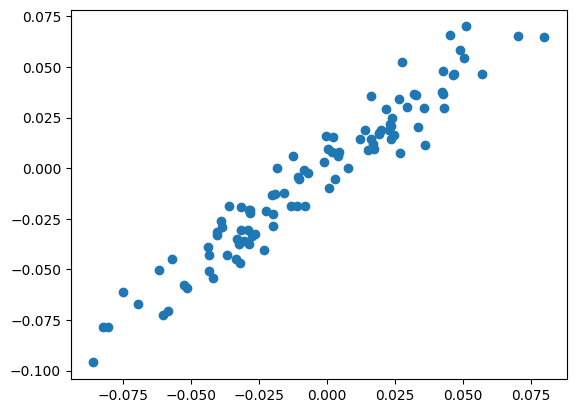

In [28]:
plt.scatter(case_1_results,case_2_results)

In [27]:
kendalltau(case_1_results,case_3_results)

SignificanceResult(statistic=0.18155414685161195, pvalue=0.01790427330794475)

Text(0, 0.5, 'case 3 tau')

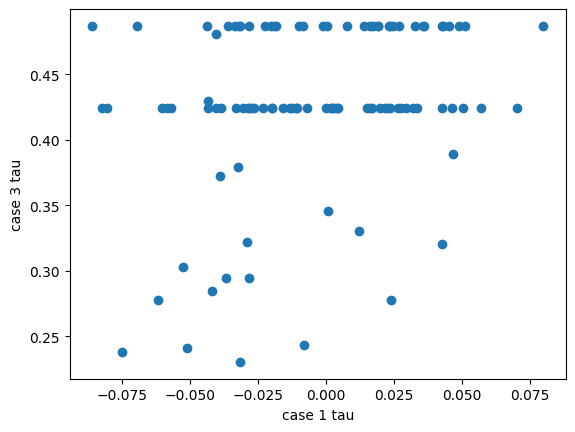

In [31]:
plt.scatter(case_1_results,case_3_results)
plt.xlabel('case 1 tau')
plt.ylabel('case 3 tau')

In [32]:
kendalltau(case_1_results,case_4_results)

SignificanceResult(statistic=0.1968481103092206, pvalue=0.010257203013449472)

Text(0, 0.5, 'case 4 tau')

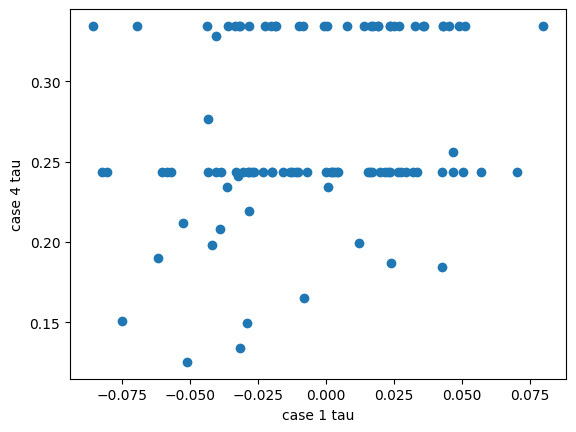

In [34]:
plt.scatter(case_1_results,case_4_results)
plt.xlabel('case 1 tau')
plt.ylabel('case 4 tau')

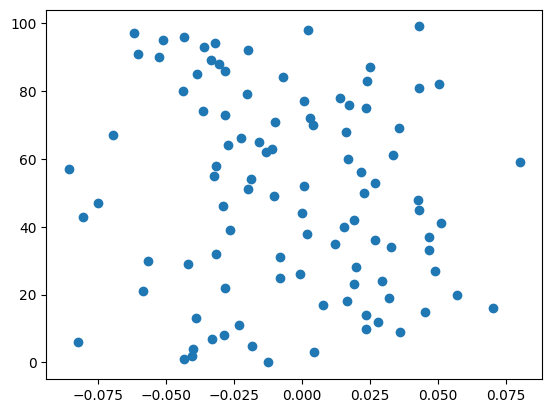

In [23]:
plt.scatter(case_1_results,np.arange(0,len(case_1_results)))

In [23]:
tvsum = h5py.File('Data/Metadata/tvsum_metadata.h5')

In [22]:
tvsum_averages = {'case_1':[],'case_2':[],'case_3':[],'case_4':[]}

In [ ]:
for key in tvsum.keys():
    results = compute_and_return_random(key,tvsum)
    tvsum_averages['case_1'].append(results[0])
    tvsum_averages['case_2'].append(results[1])
    tvsum_averages['case_3'].append(results[2])
    tvsum_averages['case_4'].append(results[3])


print('Dataset averages:')
print(f'Case 1: {np.mean(tvsum_averages["case_1"])}')
print(f'Case 2: {np.mean(tvsum_averages["case_2"])}')
print(f'Case 3: {np.mean(tvsum_averages["case_3"])}')
print(f'Case 4: {np.mean(tvsum_averages["case_4"])}')

Dataset averages:
Case 1: -0.0006897343619803557
Case 2: -0.0004987060717844936
Case 3: 0.5417775306553165
Case 4: 0.4666722285406884


In [35]:
signal = tvsum['video_2']['user_score'][...]

In [33]:
tvsum_averages = {'case_1':[],'case_2':[],'case_3':[],'case_4':[]}

In [34]:
for key in tvsum.keys():
    results = compute_and_return_gt(key,tvsum)
    tvsum_averages['case_1'].append(results[0])
    tvsum_averages['case_2'].append(results[1])
    tvsum_averages['case_3'].append(results[2])
    tvsum_averages['case_4'].append(results[3])


print('Dataset averages:')
print(f'Case 1: {np.mean(tvsum_averages["case_1"])}')
print(f'Case 2: {np.mean(tvsum_averages["case_2"])}')
print(f'Case 3: {np.mean(tvsum_averages["case_3"])}')
print(f'Case 4: {np.mean(tvsum_averages["case_4"])}')

Dataset averages:
Case 1: 1.0
Case 2: 0.939080695047965
Case 3: 0.616874468681558
Case 4: 0.6009038574302841


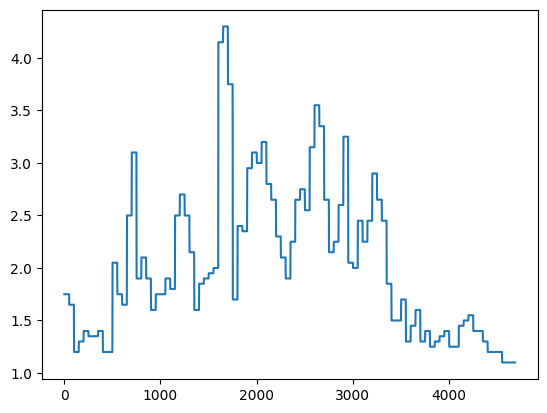

In [36]:
plt.plot(signal.mean(0))

In [37]:
import ruptures

In [38]:
pelt = ruptures.Pelt(model='l2',jump =1 ,min_size =2)

In [39]:
optimal_points = pelt.fit(signal.mean(0)[::30])

In [40]:
penalty_value = 2 # beta
result = pelt.predict(pen=penalty_value)

In [41]:
result

[17, 54, 59, 112, 157]